# Zelle 1: Imports & Indizes laden

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Berechnete Perk-Indizes aus Tag 3 Teil 1 laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')

print(f"Indizes für {len(df_indices):,} Nutzer geladen.")
df_indices.head()

Indizes für 50,000 Nutzer geladen.


,user_id,meal_index,baggage_index,cancellation_index,bargain_hunter_index,free_night_index
0,55,0.67141,0.97002,0.94416,0.52349,0.44446
1,88,0.93878,0.86556,0.45264,0.38132,0.90277
2,134,0.46166,0.79621,0.45264,0.80586,0.54905
3,207,0.39477,0.84089,0.94416,0.94560,0.25223
4,394,0.93363,0.86556,0.98105,0.91994,0.85866


# Zelle 2: Minimum-Rank-Segmentation durchführen

In [3]:
index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']

# Mapping von Index-Namen zu den offiziellen Perk-Bezeichnungen von Elena Tarrant
perk_mapping = {
    'meal_index': 'free_hotel_meal',
    'baggage_index': 'free_checked_bag',
    'cancellation_index': 'no_cancellation_fees',
    'bargain_hunter_index': 'exclusive_discounts',
    'free_night_index': '1_night_free_hotel_with_flight'
}

# 1. Absteigendes Ranking (Höchster Wert = Rang 1)
df_ranks = pd.DataFrame({'user_id': df_indices['user_id']})

for col in index_cols:
    # rank(ascending=False) sorgt dafür, dass der beste Score Rang 1 bekommt
    df_ranks[col + '_rank'] = df_indices[col].rank(ascending=False, method='min')

rank_cols = [col + '_rank' for col in index_cols]

# 2. Den besten Rang (Minimum Rank) pro User ermitteln
df_ranks['best_rank_col'] = df_ranks[rank_cols].idxmin(axis=1)

# 3. Den zugewiesenen Perk mappen (Entfernen des '_rank'-Suffixes und Anwenden des Mappings)
df_ranks['assigned_index'] = df_ranks['best_rank_col'].str.replace('_rank', '')
df_ranks['assigned_perk'] = df_ranks['assigned_index'].map(perk_mapping)

# Ergebnis-Übersicht
print("=== Zuweisungs-Ergebnis (Fuzzy / Minimum Rank Segmentation) ===")
perk_counts = df_ranks['assigned_perk'].value_counts()
print(perk_counts)

=== Zuweisungs-Ergebnis (Fuzzy / Minimum Rank Segmentation) ===
assigned_perk
no_cancellation_fees              36892
free_checked_bag                   4025
1_night_free_hotel_with_flight     3652
free_hotel_meal                    2778
exclusive_discounts                2653
Name: count, dtype: int64


# Zelle 3: Visualisierung der Perk-Verteilung

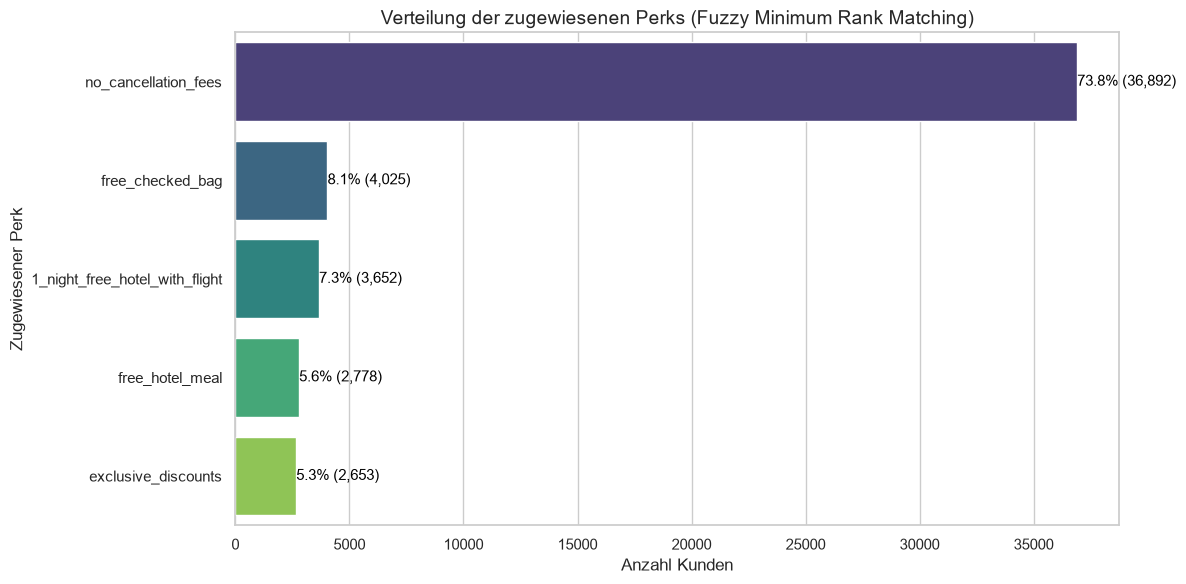

In [7]:
# Balkendiagramm der Perk-Verteilung
plt.figure(figsize=(12, 6))
ax = sns.barplot(x=perk_counts.values, y=perk_counts.index, hue=perk_counts.index, palette="viridis")

plt.title("Verteilung der zugewiesenen Perks (Fuzzy Minimum Rank Matching)", fontsize=14)
plt.xlabel("Anzahl Kunden")
plt.ylabel("Zugewiesener Perk")

# Prozentuale Beschriftung an den Balken
total = len(df_ranks)
for p in ax.patches:
    percentage = f'{100 * p.get_width() / total:.1f}% ({int(p.get_width()):,})'
    ax.annotate(percentage, (p.get_width() + 15, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=11, color='black')

plt.tight_layout()
plt.show()